In [35]:
%pip install pandas numpy scikit-learn statsmodels matplotlib seaborn scipy

# Import libraries

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report
import statsmodels.api as sm

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 120)

print("Libraries imported successfully!")

Libraries imported successfully!


# Load the COMPAS dataset

In [37]:
url = (
    "https://github.com/propublica/compas-analysis/"
    "raw/master/compas-scores-two-years.csv"
)
df = pd.read_csv(url)
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (7214, 53)


,id,name,first,last,compas_screening_date,sex,dob,age,age_cat,race,juv_fel_count,decile_score,juv_misd_count,juv_other_count,priors_count,days_b_screening_arrest,c_jail_in,c_jail_out,c_case_number,c_offense_date,c_arrest_date,c_days_from_compas,c_charge_degree,c_charge_desc,is_recid,r_case_number,r_charge_degree,r_days_from_arrest,r_offense_date,r_charge_desc,r_jail_in,r_jail_out,violent_recid,is_violent_recid,vr_case_number,vr_charge_degree,vr_offense_date,vr_charge_desc,type_of_assessment,decile_score.1,score_text,screening_date,v_type_of_assessment,v_decile_score,v_score_text,v_screening_date,in_custody,out_custody,priors_count.1,start,end,event,two_year_recid
0,1,miguel hernandez,miguel,hernandez,2013-08-14,Male,1947-04-18,69,Greater than 45,Other,0,1,0,0,0,-1.0,2013-08-13 06:03:42,2013-08-14 05:41:20,13011352CF10A,2013-08-13,NaN,1.0,F,Aggravated Assault w/Firearm,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,Risk of Recidivism,1,Low,2013-08-14,Risk of Violence,1,Low,2013-08-14,2014-07-07,2014-07-14,0,0,327,0,0
1,3,kevon dixon,kevon,dixon,2013-01-27,Male,1982-01-22,34,25 - 45,African-American,0,3,0,0,0,-1.0,2013-01-26 03:45:27,2013-02-05 05:36:53,13001275CF10A,2013-01-26,NaN,1.0,F,Felony Battery w/Prior Convict,1,13009779CF10A,(F3),NaN,2013-07-05,Felony Battery (Dom Strang),NaN,NaN,NaN,1,13009779CF10A,(F3),2013-07-05,Felony Battery (Dom Strang),Risk of Recidivism,3,Low,2013-01-27,Risk of Violence,1,Low,2013-01-27,2013-01-26,2013-02-05,0,9,159,1,1
2,4,ed philo,ed,philo,2013-04-14,Male,1991-05-14,24,Less than 25,African-American,0,4,0,1,4,-1.0,2013-04-13 04:58:34,2013-04-14 07:02:04,13005330CF10A,2013-04-13,NaN,1.0,F,Possession of Cocaine,1,13011511MM10A,(M1),0.0,2013-06-16,Driving Under The Influence,2013-06-16,2013-06-16,NaN,0,NaN,NaN,NaN,NaN,Risk of Recidivism,4,Low,2013-04-14,Risk of Violence,3,Low,2013-04-14,2013-06-16,2013-06-16,4,0,63,0,1
3,5,marcu brown,marcu,brown,2013-01-13,Male,1993-01-21,23,Less than 25,African-American,0,8,1,0,1,NaN,NaN,NaN,13000570CF10A,2013-01-12,NaN,1.0,F,Possession of Cannabis,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,Risk of Recidivism,8,High,2013-01-13,Risk of Violence,6,Medium,2013-01-13,NaN,NaN,1,0,1174,0,0
4,6,bouthy pierrelouis,bouthy,pierrelouis,2013-03-26,Male,1973-01-22,43,25 - 45,Other,0,1,0,0,2,NaN,NaN,NaN,12014130CF10A,NaN,2013-01-09,76.0,F,arrest case no charge,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,Risk of Recidivism,1,Low,2013-03-26,Risk of Violence,1,Low,2013-03-26,NaN,NaN,2,0,1102,0,0


# Understand the dataset

In [38]:
# Column names
print("Columns:")
print(df.columns.tolist())

# Data types and non-missing values
print("\nDataset information:")
df.info()

# Basic statistical summary
print("\nNumerical summary:")
display(df.describe().T)

# Missing values
print("\nMissing values per column:")
missing = df.isnull().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("missing_count"))

Columns:
['id', 'name', 'first', 'last', 'compas_screening_date', 'sex', 'dob', 'age', 'age_cat', 'race', 'juv_fel_count', 'decile_score', 'juv_misd_count', 'juv_other_count', 'priors_count', 'days_b_screening_arrest', 'c_jail_in', 'c_jail_out', 'c_case_number', 'c_offense_date', 'c_arrest_date', 'c_days_from_compas', 'c_charge_degree', 'c_charge_desc', 'is_recid', 'r_case_number', 'r_charge_degree', 'r_days_from_arrest', 'r_offense_date', 'r_charge_desc', 'r_jail_in', 'r_jail_out', 'violent_recid', 'is_violent_recid', 'vr_case_number', 'vr_charge_degree', 'vr_offense_date', 'vr_charge_desc', 'type_of_assessment', 'decile_score.1', 'score_text', 'screening_date', 'v_type_of_assessment', 'v_decile_score', 'v_score_text', 'v_screening_date', 'in_custody', 'out_custody', 'priors_count.1', 'start', 'end', 'event', 'two_year_recid']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7214 entries, 0 to 7213
Data columns (total 53 columns):
 #   Column                   N

,count,mean,std,min,25%,50%,75%,max
id,7214.0,5501.255753,3175.706870,1.0,2735.25,5509.5,8246.5,11001.0
age,7214.0,34.817993,11.888922,18.0,25.00,31.0,42.0,96.0
juv_fel_count,7214.0,0.067230,0.473972,0.0,0.00,0.0,0.0,20.0
decile_score,7214.0,4.509565,2.856396,1.0,2.00,4.0,7.0,10.0
juv_misd_count,7214.0,0.090934,0.485239,0.0,0.00,0.0,0.0,13.0
juv_other_count,7214.0,0.109371,0.501586,0.0,0.00,0.0,0.0,17.0
priors_count,7214.0,3.472415,4.882538,0.0,0.00,2.0,5.0,38.0
days_b_screening_arrest,6907.0,3.304763,75.809505,-414.0,-1.00,-1.0,0.0,1057.0
c_days_from_compas,7192.0,57.731368,329.740215,0.0,1.00,1.0,2.0,9485.0
is_recid,7214.0,0.481148,0.499679,0.0,0.00,0.0,1.0,1.0



Missing values per column:


,missing_count
violent_recid,7214
vr_charge_degree,6395
vr_offense_date,6395
vr_case_number,6395
vr_charge_desc,6395
c_arrest_date,6077
r_jail_in,4898
r_days_from_arrest,4898
r_jail_out,4898
r_charge_desc,3801


# Check the required target variables

In [39]:
required_columns = ["decile_score", "is_recid"]

for col in required_columns:
    if col in df.columns:
        print(f"\n{col}:")
        print(df[col].value_counts(dropna=False).head(15))
    else:
        print(f"\nColumn not found: {col}")

print("\nPotential demographic and predictor columns:")
display(
    df[
        [c for c in [
            "age", "sex", "race", "age_cat",
            "priors_count", "c_charge_degree",
            "decile_score", "is_recid"
        ] if c in df.columns]
    ].head()
)


decile_score:
decile_score
1     1440
2      941
4      769
3      747
5      681
6      641
7      592
8      512
9      508
10     383
Name: count, dtype: int64

is_recid:
is_recid
0    3743
1    3471
Name: count, dtype: int64

Potential demographic and predictor columns:


,age,sex,race,age_cat,priors_count,c_charge_degree,decile_score,is_recid
0,69,Male,Other,Greater than 45,0,F,1,0
1,34,Male,African-American,25 - 45,0,F,3,1
2,24,Male,African-American,Less than 25,4,F,4,1
3,23,Male,African-American,Less than 25,1,F,8,0
4,43,Male,Other,25 - 45,2,F,1,0


# Preprocess the data
Inspect missing targets and duplicates

In [40]:
print("Duplicate rows:", df.duplicated().sum())

print("Missing decile_score:", df["decile_score"].isna().sum())
print("Missing is_recid:", df["is_recid"].isna().sum())

print("\nTarget ranges:")
print("decile_score:", df["decile_score"].min(), "to", df["decile_score"].max())
print("is_recid values:", sorted(df["is_recid"].dropna().unique()))

Duplicate rows: 0
Missing decile_score: 0
Missing is_recid: 0

Target ranges:
decile_score: 1 to 10
is_recid values: [np.int64(0), np.int64(1)]


# initial predictor features

In [41]:
candidate_features = [
    "age",
    "sex",
    "race",
    "priors_count",
    "c_charge_degree"
]

missing_columns = [
    col for col in candidate_features + ["decile_score", "is_recid"]
    if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Required columns are missing: {missing_columns}")

# Keep the columns required for the initial analysis
data = df[candidate_features + ["decile_score", "is_recid"]].copy()

# Remove records with missing target labels
data = data.dropna(subset=["decile_score", "is_recid"])

# Retain only valid binary recidivism labels
data = data[data["is_recid"].isin([0, 1])].copy()

print("Rows after target filtering:", len(data))
display(data.head())

Rows after target filtering: 7214


,age,sex,race,priors_count,c_charge_degree,decile_score,is_recid
0,69,Male,Other,0,F,1,0
1,34,Male,African-American,0,F,3,1
2,24,Male,African-American,4,F,4,1
3,23,Male,African-American,1,F,8,0
4,43,Male,Other,2,F,1,0


# Inspect outliers before deciding how to handle them

,count,mean,std,min,25%,50%,75%,max
age,7214.0,34.817993,11.888922,18.0,25.0,31.0,42.0,96.0
priors_count,7214.0,3.472415,4.882538,0.0,0.0,2.0,5.0,38.0


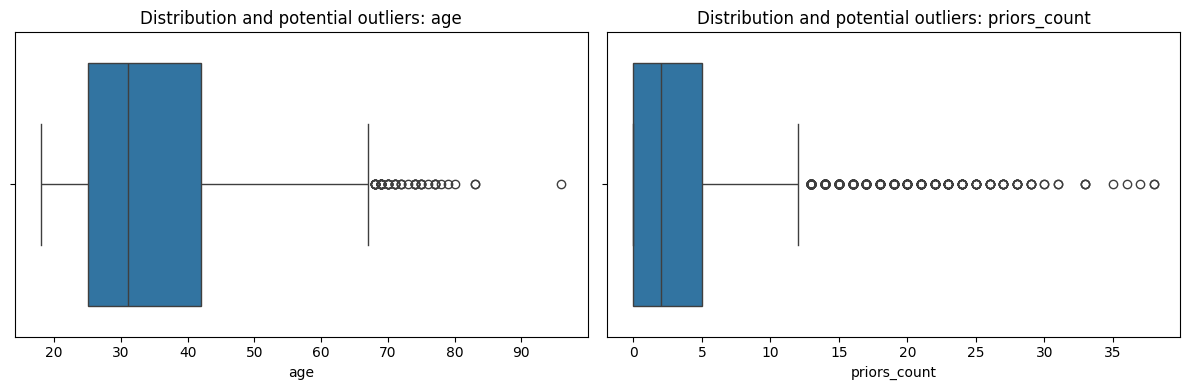

In [42]:
numeric_features = ["age", "priors_count"]

display(data[numeric_features].describe().T)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col in zip(axes, numeric_features):
    sns.boxplot(x=data[col], ax=ax)
    ax.set_title(f"Distribution and potential outliers: {col}")

plt.tight_layout()
plt.show()

# Finalize preprocessing without data leakage

# Create the train-test split

In [43]:
from sklearn.model_selection import train_test_split

FEATURES = [
    "age",
    "priors_count",
    "sex",
    "race",
    "c_charge_degree"
]

TARGET_A = "decile_score"
TARGET_B = "is_recid"

X = data[FEATURES].copy()
y_a = data[TARGET_A].copy()
y_b = data[TARGET_B].astype(int).copy()

# Keep both targets and predictors aligned in the same split.
X_train, X_test, y_a_train, y_a_test, y_b_train, y_b_test = (
    train_test_split(
        X,
        y_a,
        y_b,
        test_size=0.30,
        random_state=968,
        stratify=y_b
    )
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training percentage:", round(len(X_train) / len(data) * 100, 2))
print("Testing percentage:", round(len(X_test) / len(data) * 100, 2))

assert len(X_train) + len(X_test) == len(data)
assert X_train.index.intersection(X_test.index).empty
assert y_a_train.index.equals(X_train.index)
assert y_b_test.index.equals(X_test.index)

print("Split validation passed!")

Training rows: 5049
Testing rows: 2165
Training percentage: 69.99
Testing percentage: 30.01
Split validation passed!


# Check the split's class distributions

In [44]:
print("Training target distribution:")
display(y_b_train.value_counts(normalize=True).sort_index().rename("proportion"))

print("Testing target distribution:")
display(y_b_test.value_counts(normalize=True).sort_index().rename("proportion"))

print("Training decile-score distribution:")
display(y_a_train.value_counts().sort_index().rename("count"))

print("Testing decile-score distribution:")
display(y_a_test.value_counts().sort_index().rename("count"))

Training target distribution:


,proportion
is_recid,
0,0.518915
1,0.481085


Testing target distribution:


,proportion
is_recid,
0,0.518707
1,0.481293


Training decile-score distribution:


,count
decile_score,
1,1006
2,646
3,518
4,566
5,458
6,445
7,408
8,354
9,364


Testing decile-score distribution:


,count
decile_score,
1,434
2,295
3,229
4,203
5,223
6,196
7,184
8,158
9,144


# Build the preprocessing pipeline

In [45]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

NUMERIC_FEATURES = ["age", "priors_count"]
CATEGORICAL_FEATURES = ["sex", "race", "c_charge_degree"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, NUMERIC_FEATURES),
    ("categorical", categorical_pipeline, CATEGORICAL_FEATURES)
])

print("Preprocessing pipeline configured.")

Preprocessing pipeline configured.


# Verify the transformed training data

In [46]:
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

print("Transformed training shape:", X_train_transformed.shape)
print("Transformed testing shape:", X_test_transformed.shape)

assert X_train_transformed.shape[1] == X_test_transformed.shape[1]

print("Preprocessing validation passed!")

Transformed training shape: (5049, 12)
Transformed testing shape: (2165, 12)
Preprocessing validation passed!


### Data Preprocessing

The COMPAS dataset was loaded into a Pandas DataFrame containing 7,214 rows and 53 columns. Initial validation found no missing values in the two target variables, `decile_score` and `is_recid`, and no exact duplicate rows. The decile score ranged from 1 to 10, while the recidivism target contained binary values 0 and 1.

For the initial modelling experiment, five predictor variables were selected: age, prior-crime count, sex, race, and charge degree. Age and prior-crime count were treated as numerical features, while sex, race, and charge degree were treated as categorical features.

The dataset was divided into 70% training data and 30% testing data using `random_state=968`. Stratification by the recidivism target was used to approximately preserve its class proportions. Numerical predictors were configured for median imputation and standardization, while categorical predictors were configured for most-frequent imputation and one-hot encoding.

All preprocessing parameters were learned from the training set and subsequently applied to the test set. This procedure helps prevent information leakage. Potential outliers were inspected before deciding whether any treatment was justified; unusual observations were not automatically deleted. The resulting models and their fairness implications will be evaluated in subsequent sections.

# Train Model A: Linear Regression

In [47]:
# Model A: Linear Regression

linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_a_train)

# Predict decile scores on the test set
y_a_pred = linear_model.predict(X_test)

print("Model A trained successfully!")
print("First 10 actual scores:", y_a_test.head(10).tolist())
print("First 10 predicted scores:", np.round(y_a_pred[:10], 2))

Model A trained successfully!
First 10 actual scores: [3, 6, 1, 9, 5, 6, 9, 2, 5, 4]
First 10 predicted scores: [3.66 4.77 2.68 7.18 3.83 7.66 6.55 4.46 5.85 4.48]


# Train Model B: Logistic Regression


In [48]:
# Model B: Logistic Regression

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=2000))
])

logistic_model.fit(X_train, y_b_train)

# Predict probabilities and binary outcomes
y_b_prob = logistic_model.predict_proba(X_test)[:, 1]
y_b_pred = (y_b_prob >= 0.5).astype(int)

print("Model B trained successfully!")
print("First 10 actual outcomes:", y_b_test.head(10).tolist())
print("First 10 predicted probabilities:", np.round(y_b_prob[:10], 3))
print("First 10 predicted classes:", y_b_pred[:10])

Model B trained successfully!
First 10 actual outcomes: [0, 0, 0, 0, 0, 0, 1, 1, 1, 1]
First 10 predicted probabilities: [0.457 0.565 0.287 0.685 0.511 0.794 0.605 0.503 0.589 0.485]
First 10 predicted classes: [0 1 0 1 1 1 1 1 1 0]


# Evaluate Model B

In [49]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("Accuracy:", round(accuracy_score(y_b_test, y_b_pred), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_b_test, y_b_pred))

print("\nClassification Report:")
print(classification_report(y_b_test, y_b_pred, zero_division=0))

Accuracy: 0.6748

Confusion Matrix:
[[790 333]
 [371 671]]

Classification Report:
              precision    recall  f1-score   support

           0       0.68      0.70      0.69      1123
           1       0.67      0.64      0.66      1042

    accuracy                           0.67      2165
   macro avg       0.67      0.67      0.67      2165
weighted avg       0.67      0.67      0.67      2165



# Compare the two thresholding approaches

In [50]:
# Threshold Model A at the median predicted decile score
median_threshold = np.median(y_a_pred)
linear_class = (y_a_pred >= median_threshold).astype(int)

# Threshold Model B at probability 0.5
logistic_class = (y_b_prob >= 0.5).astype(int)

# Agreement/disagreement between the two classifications
comparison_matrix = confusion_matrix(
    linear_class,
    logistic_class,
    labels=[0, 1]
)

mismatches = np.sum(linear_class != logistic_class)
mismatch_percentage = mismatches / len(X_test) * 100

print("Linear model median threshold:", round(median_threshold, 4))
print("\nConfusion matrix (rows = Linear, columns = Logistic):")
print(comparison_matrix)
print("\nMismatched cases:", mismatches)
print("Mismatch percentage:", round(mismatch_percentage, 2), "%")

Linear model median threshold: 4.6965

Confusion matrix (rows = Linear, columns = Logistic):
[[1015   67]
 [ 146  937]]

Mismatched cases: 213
Mismatch percentage: 9.84 %


In [51]:
from sklearn.metrics import accuracy_score

part1_results = {
    "test_rows": len(X_test),
    "linear_median_threshold": median_threshold,
    "logistic_accuracy": accuracy_score(y_b_test, y_b_pred),
    "agreement_cases": int(np.sum(linear_class == logistic_class)),
    "mismatched_cases": int(np.sum(linear_class != logistic_class)),
    "mismatch_percentage": mismatch_percentage
}

display(pd.DataFrame(
    list(part1_results.items()),
    columns=["Metric", "Value"]
))

,Metric,Value
0,test_rows,2165.000000
1,linear_median_threshold,4.696475
2,logistic_accuracy,0.674827
3,agreement_cases,1952.000000
4,mismatched_cases,213.000000
5,mismatch_percentage,9.838337


# Begin Part 2.1: Simpson's Paradox Hunt

In [52]:
print("Race group counts:")
display(data["race"].value_counts())

print("\nRecidivism rate by race:")
display(
    data.groupby("race", observed=True)["is_recid"]
    .agg(["count", "mean"])
    .rename(columns={"mean": "recidivism_rate"})
)

Race group counts:


,count
race,
African-American,3696
Caucasian,2454
Hispanic,637
Other,377
Asian,32
Native American,18



Recidivism rate by race:


,count,recidivism_rate
race,,
African-American,3696,0.550866
Asian,32,0.343750
Caucasian,2454,0.417685
Hispanic,637,0.384615
Native American,18,0.611111
Other,377,0.379310


In [53]:
import statsmodels.formula.api as smf

# Keep the two comparison groups
groups = ["African-American", "Caucasian"]

analysis_data = data[
    data["race"].isin(groups)
].copy()

formula_full = (
    "is_recid ~ age + priors_count + C(sex) "
    "+ C(race) + C(c_charge_degree)"
)

formula_subgroup = (
    "is_recid ~ age + priors_count + C(sex) "
    "+ C(c_charge_degree)"
)

# Full model on the selected two-group sample
full_model = smf.logit(
    formula_full, data=analysis_data
).fit(disp=False)

# One model per race subgroup
subgroup_models = {}

for group in groups:
    subset = analysis_data[
        analysis_data["race"] == group
    ].copy()

    subgroup_models[group] = smf.logit(
        formula_subgroup, data=subset
    ).fit(disp=False)

# Compare the prior-crime-count coefficients
comparison = pd.DataFrame({
    "Full model": full_model.params,
    "African-American": subgroup_models["African-American"].params,
    "Caucasian": subgroup_models["Caucasian"].params
})

print("Coefficient comparison:")
display(comparison.loc[["priors_count"]])

print("\nFull model coefficient and p-value:")
print(full_model.params["priors_count"],
      full_model.pvalues["priors_count"])

for group, model in subgroup_models.items():
    print(f"\n{group}")
    print("Coefficient:", model.params["priors_count"])
    print("P-value:", model.pvalues["priors_count"])
    print("95% confidence interval:")
    print(model.conf_int().loc["priors_count"].tolist())

Coefficient comparison:


,Full model,African-American,Caucasian
priors_count,0.154344,0.149147,0.182346



Full model coefficient and p-value:
0.15434441725593284 5.711283490032882e-94

African-American
Coefficient: 0.1491472104624281
P-value: 1.6754007279340238e-62
95% confidence interval:
[0.13162745344954774, 0.16666696747530846]

Caucasian
Coefficient: 0.1823456522286571
P-value: 2.3768129419157355e-35
95% confidence interval:
[0.15354145036096759, 0.2111498540963466]


# Test whether the subgroup difference is statistically significant

In [54]:
import statsmodels.formula.api as smf
import numpy as np
import pandas as pd

interaction_model = smf.logit(
    "is_recid ~ age + priors_count * C(race) "
    "+ C(sex) + C(c_charge_degree)",
    data=analysis_data
).fit(disp=False)

# Display the interaction coefficient and its significance
interaction_term = [
    name for name in interaction_model.params.index
    if "priors_count:C(race)" in name
][0]

result = pd.DataFrame({
    "Coefficient": [interaction_model.params[interaction_term]],
    "P-value": [interaction_model.pvalues[interaction_term]],
    "CI Lower": [interaction_model.conf_int().loc[interaction_term, 0]],
    "CI Upper": [interaction_model.conf_int().loc[interaction_term, 1]]
}, index=[interaction_term])

display(result)

if interaction_model.pvalues[interaction_term] < 0.05:
    print("Evidence of a statistically significant interaction.")
else:
    print("No statistically significant interaction detected.")

,Coefficient,P-value,CI Lower,CI Upper
priors_count:C(race)[T.Caucasian],0.043638,0.008613,0.011081,0.076195


Evidence of a statistically significant interaction.


# Part 2.2: Omitted-Variable Bias

In [55]:
# Full model
full_ovb = smf.logit(
    "is_recid ~ age + priors_count + C(sex) "
    "+ C(race) + C(c_charge_degree)",
    data=analysis_data
).fit(disp=False)

# Reduced model: age removed
reduced_ovb = smf.logit(
    "is_recid ~ priors_count + C(sex) "
    "+ C(race) + C(c_charge_degree)",
    data=analysis_data
).fit(disp=False)

print("Full model fitted successfully!")
print("Reduced model fitted successfully!")

Full model fitted successfully!
Reduced model fitted successfully!


# Compare four predictor coefficients

In [56]:
# Predictors present in both models
common_predictors = [
    name for name in full_ovb.params.index
    if name in reduced_ovb.params.index
    and name != "Intercept"
]

comparison_ovb = pd.DataFrame({
    "Full coefficient": full_ovb.params[common_predictors],
    "Reduced coefficient": reduced_ovb.params[common_predictors]
})

comparison_ovb["Percentage change"] = (
    (comparison_ovb["Reduced coefficient"]
     - comparison_ovb["Full coefficient"])
    / comparison_ovb["Full coefficient"].abs()
) * 100

comparison_ovb["Absolute percentage change"] = (
    comparison_ovb["Percentage change"].abs()
)

display(comparison_ovb.round(4))

largest_shift = comparison_ovb[
    "Absolute percentage change"
].idxmax()

print("\nLargest percentage shift:", largest_shift)
print(
    "Absolute percentage change:",
    round(
        comparison_ovb.loc[
            largest_shift, "Absolute percentage change"
        ], 2
    ),
    "%"
)

,Full coefficient,Reduced coefficient,Percentage change,Absolute percentage change
C(sex)[T.Male],0.3660,0.3617,-1.1670,1.1670
C(race)[T.Caucasian],-0.0905,-0.3296,-264.0634,264.0634
C(c_charge_degree)[T.M],-0.1168,-0.2139,-83.1617,83.1617
priors_count,0.1543,0.1235,-19.9610,19.9610



Largest percentage shift: C(race)[T.Caucasian]
Absolute percentage change: 264.06 %


# Part 2.3: Adversarial Subset Construction
Identify confident errors

In [57]:
# Create a results table for the test set
adversarial_results = X_test.copy()

adversarial_results["actual"] = y_b_test
adversarial_results["predicted_probability"] = y_b_prob
adversarial_results["predicted_class"] = y_b_pred

# Confident false positives
false_positives = adversarial_results[
    (adversarial_results["predicted_probability"] >= 0.75) &
    (adversarial_results["actual"] == 0)
].copy()

false_positives["error_type"] = "False Positive"

# Confident false negatives
false_negatives = adversarial_results[
    (adversarial_results["predicted_probability"] <= 0.25) &
    (adversarial_results["actual"] == 1)
].copy()

false_negatives["error_type"] = "False Negative"

# Combine both types
confident_errors = pd.concat([
    false_positives,
    false_negatives
])

print("Confident false positives:", len(false_positives))
print("Confident false negatives:", len(false_negatives))
print("Total confident errors:", len(confident_errors))
print(
    "Percentage of test set:",
    round(len(confident_errors) / len(X_test) * 100, 2),
    "%"
)

Confident false positives: 28
Confident false negatives: 48
Total confident errors: 76
Percentage of test set: 3.51 %


# Select up to 50 cases and inspect their demographics

In [58]:
# Use a reproducible sample if more than 50 cases exist
if len(confident_errors) > 50:
    adversarial_subset = confident_errors.sample(
        n=50, random_state=968
    )
else:
    adversarial_subset = confident_errors.copy()

print("Rows selected:", len(adversarial_subset))

display(adversarial_subset.head(10))

# Compare age and gender distributions
for column in ["age", "sex", "race"]:
    print(f"\nDistribution of {column}:")

    comparison = pd.concat([
        X_test[column].value_counts(normalize=True).rename("Full test set"),
        adversarial_subset[column].value_counts(normalize=True).rename(
            "Adversarial subset"
        )
    ], axis=1).fillna(0) * 100

    display(comparison.round(2))

# Error-type distribution
display(
    adversarial_subset["error_type"]
    .value_counts()
    .rename("count")
    .to_frame()
)

# Save the selected cases for reproducibility
adversarial_subset.to_csv(
    "compas_adversarial_subset.csv",
    index=True
)

print("Saved compas_adversarial_subset.csv")

Rows selected: 50


,age,priors_count,sex,race,c_charge_degree,actual,predicted_probability,predicted_class,error_type
3132,40,15,Male,African-American,F,0,0.840224,1,False Positive
2352,54,1,Male,Caucasian,M,1,0.207817,0,False Negative
1011,51,0,Male,Hispanic,F,1,0.189682,0,False Negative
7096,65,2,Male,Hispanic,M,1,0.131959,0,False Negative
1967,50,0,Male,Caucasian,F,1,0.230977,0,False Negative
4999,59,2,Male,Caucasian,M,1,0.196333,0,False Negative
7005,56,0,Male,Caucasian,M,1,0.170509,0,False Negative
3596,53,1,Male,Hispanic,M,1,0.182819,0,False Negative
4086,44,0,Female,Caucasian,M,1,0.195606,0,False Negative
4872,52,0,Male,African-American,F,1,0.233590,0,False Negative



Distribution of age:


,Full test set,Adversarial subset
age,,
24,5.17,2.0
27,4.85,0.0
25,4.71,4.0
23,4.57,0.0
26,4.30,2.0
21,4.16,0.0
22,3.97,0.0
30,3.88,0.0
31,3.79,4.0



Distribution of sex:


,Full test set,Adversarial subset
sex,,
Male,80.42,82.0
Female,19.58,18.0



Distribution of race:


,Full test set,Adversarial subset
race,,
African-American,51.22,36.0
Caucasian,35.38,50.0
Hispanic,8.64,14.0
Other,4.25,0.0
Asian,0.42,0.0
Native American,0.09,0.0


,count
error_type,
False Negative,31
False Positive,19


Saved compas_adversarial_subset.csv


# Investigate common characteristics

In [59]:
print("Prior-crime count comparison:")
display(
    adversarial_subset["priors_count"]
    .describe()
    .to_frame("Adversarial subset")
)

print("\nAge comparison:")
display(
    adversarial_subset["age"]
    .describe()
    .to_frame("Adversarial subset")
)

print("\nAverage predicted probability by error type:")
display(
    adversarial_subset.groupby("error_type")[
        "predicted_probability"
    ].agg(["count", "mean", "min", "max"])
)

Prior-crime count comparison:


,Adversarial subset
count,50.000000
mean,6.000000
std,7.191265
min,0.000000
25%,0.250000
50%,2.000000
75%,11.750000
max,24.000000



Age comparison:


,Adversarial subset
count,50.000000
mean,47.860000
std,11.988106
min,24.000000
25%,38.500000
50%,51.000000
75%,56.000000
max,69.000000



Average predicted probability by error type:


,count,mean,min,max
error_type,,,,
False Negative,31,0.196386,0.102728,0.241746
False Positive,19,0.818282,0.751074,0.960061


# Part 2.4: Fairness trade-off analysis
Calculate the three fairness metrics

In [60]:
import numpy as np
import pandas as pd

# Combine test-set outcomes, probabilities, and demographics
fairness_data = X_test[["race"]].copy()
fairness_data["actual"] = y_b_test
fairness_data["probability"] = y_b_prob

GROUP_A = "African-American"
GROUP_B = "Caucasian"

fairness_data = fairness_data[
    fairness_data["race"].isin([GROUP_A, GROUP_B])
].copy()


def safe_ratio(a, b):
    """Return NaN when the ratio is undefined."""
    if pd.isna(a) or pd.isna(b) or b == 0:
        return np.nan
    return a / b


def group_metrics(group_df, threshold):
    actual = group_df["actual"].to_numpy()
    predicted = (
        group_df["probability"].to_numpy() >= threshold
    ).astype(int)

    tp = np.sum((actual == 1) & (predicted == 1))
    fp = np.sum((actual == 0) & (predicted == 1))
    tn = np.sum((actual == 0) & (predicted == 0))
    fn = np.sum((actual == 1) & (predicted == 0))

    positive_rate = predicted.mean()
    tpr = tp / (tp + fn) if (tp + fn) else np.nan
    fpr = fp / (fp + tn) if (fp + tn) else np.nan
    ppv = tp / (tp + fp) if (tp + fp) else np.nan

    return {
        "DP_rate": positive_rate,
        "TPR": tpr,
        "FPR": fpr,
        "PPV": ppv
    }


thresholds = np.round(np.arange(0.05, 0.951, 0.10), 2)
fairness_results = []

for threshold in thresholds:
    group_a = group_metrics(
        fairness_data[fairness_data["race"] == GROUP_A],
        threshold
    )
    group_b = group_metrics(
        fairness_data[fairness_data["race"] == GROUP_B],
        threshold
    )

    dp = safe_ratio(group_a["DP_rate"], group_b["DP_rate"])

    tpr_ratio = safe_ratio(group_a["TPR"], group_b["TPR"])
    fpr_ratio = safe_ratio(group_a["FPR"], group_b["FPR"])

    eo = (
        min(tpr_ratio, fpr_ratio)
        if not np.isnan(tpr_ratio) and not np.isnan(fpr_ratio)
        else np.nan
    )

    pp = safe_ratio(group_a["PPV"], group_b["PPV"])

    fairness_results.append({
        "Threshold": threshold,
        "DP": dp,
        "EO": eo,
        "PP": pp
    })

fairness_table = pd.DataFrame(fairness_results)

display(fairness_table.round(4))

,Threshold,DP,EO,PP
0,0.05,1.0000,1.0000,1.2782
1,0.15,1.0475,1.0170,1.2410
2,0.25,1.1771,1.0771,1.1697
3,0.35,1.3329,1.2293,1.1789
4,0.45,1.6441,1.4289,1.1110
5,0.55,2.2707,1.9731,1.1107
6,0.65,2.4902,2.0940,1.1194
7,0.75,3.5488,2.7629,1.1001
8,0.85,3.6262,2.9180,1.0286
9,0.95,3.7989,NaN,0.9091


# Draw the fairness trade-off chart

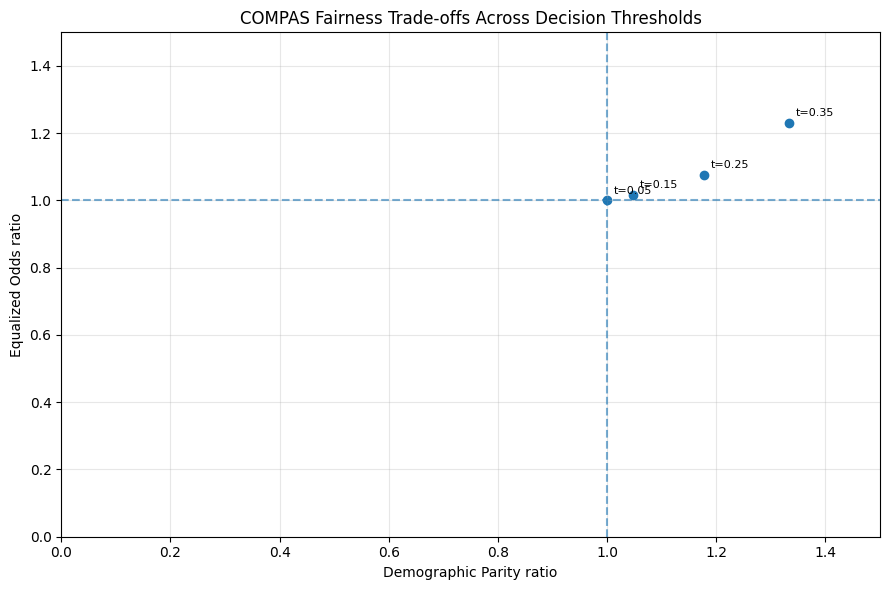

In [61]:
import matplotlib.pyplot as plt

valid = fairness_table.dropna(subset=["DP", "EO"])

plt.figure(figsize=(9, 6))

plt.scatter(valid["DP"], valid["EO"])

for _, row in valid.iterrows():
    plt.annotate(
        f't={row["Threshold"]:.2f}',
        (row["DP"], row["EO"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.axvline(1.0, linestyle="--", alpha=0.6)
plt.axhline(1.0, linestyle="--", alpha=0.6)

plt.xlim(0, 1.5)
plt.ylim(0, 1.5)

plt.xlabel("Demographic Parity ratio")
plt.ylabel("Equalized Odds ratio")
plt.title("COMPAS Fairness Trade-offs Across Decision Thresholds")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Save  fairness results

In [62]:
fairness_table.to_csv(
    "compas_fairness_metrics.csv",
    index=False
)

print("Saved compas_fairness_metrics.csv")

Saved compas_fairness_metrics.csv


# **# Model classification differences**


# Verify the train-test split and model predictions

In [63]:
# Verify split sizes and index alignment
assert len(X_train) + len(X_test) == len(data)
assert X_train.index.intersection(X_test.index).empty

assert len(y_a_test) == len(y_a_pred)
assert len(y_b_test) == len(y_b_prob)
assert len(y_b_test) == len(y_b_pred)

# Verify predicted values are valid
assert np.isfinite(y_a_pred).all()
assert np.isfinite(y_b_prob).all()
assert np.all((y_b_prob >= 0) & (y_b_prob <= 1))

print("Split and prediction checks passed.")
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Split and prediction checks passed.
Training rows: 5049
Testing rows: 2165


# Verify Part 1 results

In [64]:
from sklearn.metrics import accuracy_score, confusion_matrix

# Recalculate the results from predictions
verified_accuracy = accuracy_score(y_b_test, y_b_pred)

verified_mismatches = int(
    np.sum(linear_class != logistic_class)
)

verified_mismatch_percentage = (
    verified_mismatches / len(X_test) * 100
)

verified_median = float(np.median(y_a_pred))

verification_results = pd.DataFrame({
    "Metric": [
        "Test observations",
        "Linear regression median threshold",
        "Logistic regression accuracy",
        "Agreement cases",
        "Mismatched cases",
        "Mismatch percentage"
    ],
    "Value": [
        len(X_test),
        verified_median,
        verified_accuracy,
        int(np.sum(linear_class == logistic_class)),
        verified_mismatches,
        verified_mismatch_percentage
    ]
})

display(verification_results.round(4))

assert verified_mismatches == 213
assert len(X_test) == 2165

print("Part 1 verification passed.")

,Metric,Value
0,Test observations,2165.0000
1,Linear regression median threshold,4.6965
2,Logistic regression accuracy,0.6748
3,Agreement cases,1952.0000
4,Mismatched cases,213.0000
5,Mismatch percentage,9.8383


Part 1 verification passed.


# Verify the subgroup and omitted-variable results

In [65]:
# Check that the fitted models contain the expected predictors
assert "priors_count" in full_model.params.index
assert "priors_count" in subgroup_models["African-American"].params.index
assert "priors_count" in subgroup_models["Caucasian"].params.index

assert "priors_count" in full_ovb.params.index
assert "priors_count" in reduced_ovb.params.index
assert "age" in full_ovb.params.index
assert "age" not in reduced_ovb.params.index

# Verify interaction significance
interaction_p = interaction_model.pvalues[interaction_term]

print("Interaction coefficient:",
      interaction_model.params[interaction_term])
print("Interaction p-value:", interaction_p)

print("\nFull-model priors_count coefficient:",
      full_ovb.params["priors_count"])
print("Reduced-model priors_count coefficient:",
      reduced_ovb.params["priors_count"])

assert np.isfinite(interaction_p)

print("\nRegression verification passed.")

Interaction coefficient: 0.04363794063530891
Interaction p-value: 0.008612795606969023

Full-model priors_count coefficient: 0.15434441725593284
Reduced-model priors_count coefficient: 0.12353566304048197

Regression verification passed.


# Verify adversarial-subset results

In [66]:
# Every selected case must meet the confident-error definition
assert len(adversarial_subset) <= 50

assert (
    (
        (adversarial_subset["predicted_probability"] >= 0.75) &
        (adversarial_subset["actual"] == 0)
    ) |
    (
        (adversarial_subset["predicted_probability"] <= 0.25) &
        (adversarial_subset["actual"] == 1)
    )
).all()

assert (
    adversarial_subset["error_type"].isin(
        ["False Positive", "False Negative"]
    )
).all()

print("Total qualifying confident errors:", len(confident_errors))
print("Selected adversarial rows:", len(adversarial_subset))
print("Adversarial-subset verification passed.")

Total qualifying confident errors: 76
Selected adversarial rows: 50
Adversarial-subset verification passed.


# Verify fairness calculations

In [67]:
# Check threshold coverage and saved metrics
expected_thresholds = np.round(np.arange(0.05, 0.951, 0.10), 2)

assert np.allclose(
    fairness_table["Threshold"].to_numpy(),
    expected_thresholds
)

assert fairness_table["DP"].notna().any()
assert fairness_table["PP"].notna().any()

print("Thresholds checked:", len(fairness_table))
display(fairness_table.round(4))

print("Fairness-table verification passed.")

Thresholds checked: 10


,Threshold,DP,EO,PP
0,0.05,1.0000,1.0000,1.2782
1,0.15,1.0475,1.0170,1.2410
2,0.25,1.1771,1.0771,1.1697
3,0.35,1.3329,1.2293,1.1789
4,0.45,1.6441,1.4289,1.1110
5,0.55,2.2707,1.9731,1.1107
6,0.65,2.4902,2.0940,1.1194
7,0.75,3.5488,2.7629,1.1001
8,0.85,3.6262,2.9180,1.0286
9,0.95,3.7989,NaN,0.9091


Fairness-table verification passed.


# Save the key results

In [68]:

verification_results.to_csv(
    "compas_part1_verification.csv",
    index=False
)

comparison_ovb.to_csv(
    "compas_omitted_variable_bias.csv"
)

fairness_table.to_csv(
    "compas_fairness_metrics.csv",
    index=False
)

adversarial_subset.to_csv(
    "compas_adversarial_subset.csv",
    index=True
)

print("Key result files saved successfully.")

Key result files saved successfully.
